### YSO Classification following Gutermuth et. al. 2009, to classify Class I and Class II YSO.

##### Note we will be only allowed to use Phase I, since it uses IRAC (Spitzer) Data from [3.6, 4.5, 5.8, 8.0] bands.

##### (For the moment we will only use Spitzer sources)

In [2]:
import pandas as pd 
from matplotlib import pyplot as plt
from astropy.table import Table, QTable
import numpy as np

In [3]:
cat = 'glimpse_s07'

In [4]:
spitzer_sources = Table.read("../output/tables/spitzer_sources_"+cat+".tbl", format="ascii")
print(spitzer_sources)

cntr_01   dist_x     pang_x   ... color45_58 color45_80 color58_80
          arcsec      deg     ...                                 
------- --------- ----------- ... ---------- ---------- ----------
      1  2.867081  -55.508188 ...      0.471      0.367     -0.104
      1  4.406157   86.064855 ...         --         --         --
      1  8.680204  -84.956251 ...      0.342         --         --
      1 11.244409  107.572919 ...      0.204         --         --
      1 12.740404  176.146569 ...      0.662      1.394      0.732
      1 14.110753    2.108431 ...         --         --         --
      1 14.586334   88.756257 ...         --         --         --
      1 14.719587  167.971572 ...         --         --         --
      1 15.372734   23.769197 ...         --         --         --
    ...       ...         ... ...        ...        ...        ...
   1017  58.44517  134.662464 ...         --         --         --
   1017 58.593662  -82.369246 ...         --         --       

In [5]:
print(spitzer_sources["color36_45"][:3] - (spitzer_sources["mag3_6"][:3]-spitzer_sources["mag4_5"][:3]))

      color36_45      
----------------------
-4.440892098500626e-16
-4.440892098500626e-16
-9.159339953157541e-16


In [6]:
# Phase I sources
# 0.2 mag error in all four bands
print("Phase I sources:")

phase_I = spitzer_sources[(
    (spitzer_sources["d3_6m"] < 0.2) &
    (spitzer_sources["d4_5m"] < 0.2) &
    (spitzer_sources["d5_8m"] < 0.2) &
    (spitzer_sources["d8_0m"] < 0.2)
)]

print(f"{len(phase_I)}/{len(spitzer_sources)} {len(phase_I)/len(spitzer_sources)*100:.2f} % of the total sources")


Phase I sources:
77002/102073 75.44 % of the total sources


17295/102073 16.94 % of the total sources


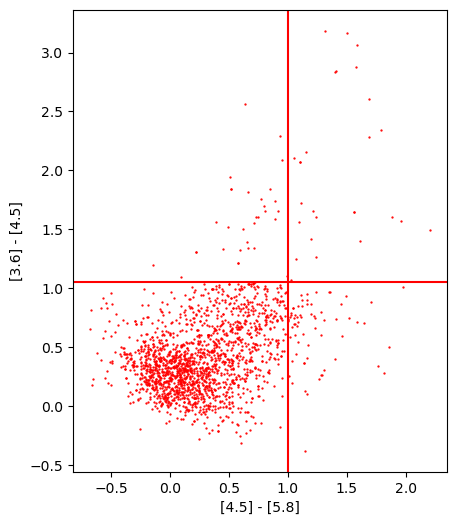

cntr_01   dist_x     pang_x   ... color45_58 color45_80 color58_80
          arcsec      deg     ...                                 
------- --------- ----------- ... ---------- ---------- ----------
      1  8.680204  -84.956251 ...      0.342         --         --
      1 11.244409  107.572919 ...      0.204         --         --
      1 12.740404  176.146569 ...      0.662      1.394      0.732
      1 14.586334   88.756257 ...         --         --         --
      1 15.959071 -142.927299 ...      0.835        1.1      0.265
      1 16.098536  114.663755 ...         --         --         --
      1 16.197893  147.058329 ...         --         --         --
      1 20.072701 -103.748083 ...     -0.063         --         --
      1 21.159044 -165.882891 ...      0.543      0.322     -0.221
    ...       ...         ... ...        ...        ...        ...
   1017 57.113042  104.184502 ...      0.255         --         --
   1017  57.76378   -113.9185 ...         --         --       

In [7]:
# PAH emission sources

phase_I_no_YSO = phase_I

phase_I = phase_I[(~(
    (phase_I["color45_58"] < 1.05) &
    (phase_I["mag4_5"] > 11.5)
    )
)]

phase_I = phase_I[(~(
    (phase_I["color45_58"] < (1.05/1.2)*(phase_I["color58_80"]-1.0)) &
    (phase_I["color58_80"] > 1.0)
))]

phase_I = phase_I[(~(
    (phase_I["color36_58"] < (1.5/2)*(phase_I["color45_80"]-1.0)) &
    (phase_I["color45_80"] > 1.0)
))]

print(f"{len(phase_I)}/{len(spitzer_sources)} {len(phase_I)/len(spitzer_sources)*100:.2f} % of the total sources")

ids = np.array(phase_I['designation'])

phase_I_no_YSO = phase_I_no_YSO[~(np.isin(phase_I_no_YSO['designation'],ids))]

_, ax = plt.subplots(figsize=(6,6))

ax.scatter(phase_I_no_YSO["color58_80"],phase_I_no_YSO["color45_58"],s=0.4,color='red',alpha=1)
#ax.scatter(phase_I["color58_80"],phase_I["color45_58"],s=0.4,color="black",alpha=1)

ax.axvline(1,color='red')
ax.axhline(1.05,color='red')

#x_min, x_max = 

ax.set_aspect("equal",adjustable="box")
ax.set_ylabel("[3.6] - [4.5]")
ax.set_xlabel("[4.5] - [5.8]")
plt.show()
print(phase_I_no_YSO)




In [8]:
# AGN sources

phase_I = phase_I[(~(
    (
        (phase_I["color45_80"] > 0.5) &
        (phase_I["mag4_5"] > 13.5 + (phase_I["color45_80"]-2.3)/0.4) &
        (phase_I["mag4_5"] > 13.5)
    ) &
    (
        (phase_I["mag4_5"] > 14+(phase_I["color45_80"]-0.5)) |
        (phase_I["mag4_5"] > 14.5 - (phase_I["color45_80"]-1.2)/0.3) |
        (phase_I["mag4_5"] > 14.5)
    )
))]

print(f"{len(phase_I)}/{len(spitzer_sources)} {len(phase_I)/len(spitzer_sources)*100:.2f} % of the total sources")

17294/102073 16.94 % of the total sources


In [9]:
# Shock emission dominated sources

phase_I = phase_I[(~(
    (phase_I["color36_45"] > (12.0/0.55)*(phase_I["color45_80"]-0.3)+0.8) &
    (phase_I["color45_58"] <= 0.85) &
    (phase_I["color36_45"] > 1.05)
))]

print(f"{len(phase_I)}/{len(spitzer_sources)} {len(phase_I)/len(spitzer_sources)*100:.2f} % of the total sources")

17272/102073 16.92 % of the total sources


In [10]:
# PAH contaminated sources

sigma_1 = phase_I["d4_5m"]+phase_I["d5_8m"]
sigma_2 = phase_I["d3_6m"]+phase_I["d4_5m"]

phase_I = phase_I[(~(
    (phase_I["color36_45"] - sigma_2 <= 1.4*(phase_I["color45_58"]+sigma_1-0.7)) &
    (phase_I["color36_45"] - sigma_2 <= 1.65)
))]


print(f"{len(phase_I)}/{len(spitzer_sources)} {len(phase_I)/len(spitzer_sources)*100:.2f} % of the total sources")

12679/102073 12.42 % of the total sources


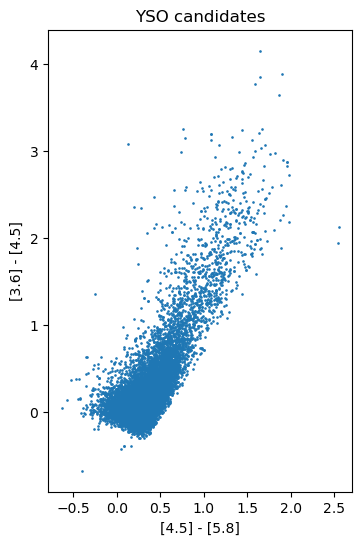

In [11]:
_, ax = plt.subplots(figsize=(6,6))

ax.scatter(phase_I['color45_58'],phase_I['color36_45'],s=0.8)

ax.set_aspect("equal",adjustable="box")
ax.set_ylabel("[3.6] - [4.5]")
ax.set_xlabel("[4.5] - [5.8]")
ax.set_title("YSO candidates")
plt.show()

In [12]:
# Class I

phase_I_class_I = phase_I[
    (phase_I["color45_58"] > 0.7) &
    (phase_I["color36_45"] > 0.7)
]
ids_I = np.array(phase_I_class_I['designation'])

# Class II
sigma_2 = phase_I["d3_6m"]+phase_I["d4_5m"]
sigma_3 = phase_I["d4_5m"] + phase_I["d8_0m"]
sigma_4 = phase_I["d3_6m"] + phase_I["d5_8m"]

phase_I_class_II = phase_I[
    (phase_I["color45_80"] -sigma_3 > 0.5) &
    (phase_I["color36_58"] - sigma_4 > 0.35) &
    (phase_I["color36_58"] + sigma_4 <= (0.14/0.04)*(phase_I["color45_80"]-sigma_3-0.5)+0.5) &
    (phase_I["color36_45"] - sigma_2 > 0.15) &
    ~(np.isin(phase_I['designation'],ids_I))
]

In [13]:

ids_I = np.array(phase_I_class_I['designation'])
ids_II = np.array(phase_I_class_II['designation'])

phase_I_no_class = phase_I[
    ~(np.isin(phase_I['designation'],ids_I)) &
    ~(np.isin(phase_I['designation'],ids_II))
]
len(phase_I_no_class)

print(f"{len(phase_I)} = {len(phase_I_class_I)}+{len(phase_I_class_II)}+{len(phase_I_no_class)} = {len(phase_I_class_I)+len(phase_I_class_II)+len(phase_I_no_class)}")

12679 = 988+342+11349 = 12679


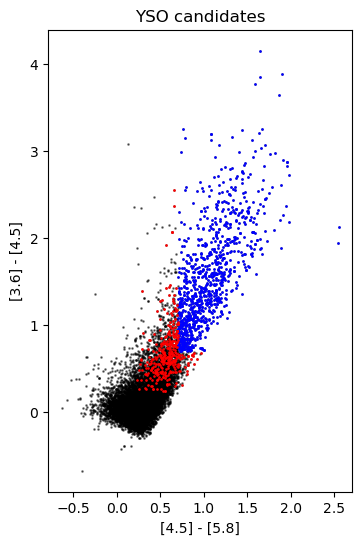

In [14]:
_, ax = plt.subplots(figsize=(6,6))

ax.scatter(phase_I["color45_58"],phase_I["color36_45"],s=0.8,color="black",alpha=0.5)
ax.scatter(phase_I_class_I['color45_58'],phase_I_class_I['color36_45'],s=0.8,color='blue')
ax.scatter(phase_I_class_II['color45_58'],phase_I_class_II['color36_45'],s=0.8,color='red')


ax.set_aspect("equal",adjustable="box")
ax.set_ylabel("[3.6] - [4.5]")
ax.set_xlabel("[4.5] - [5.8]")
ax.set_title("YSO candidates")
plt.savefig('YSO_classification_'+cat+'.png',format='png',dpi=300)
plt.show()

In [15]:
# Phase II

from astropy.table import Table
import numpy as np 


cat = 'glimpse_s07'

spitzer_sources = Table.read('../output/tables/'+cat+'_2mass.tbl',format='ascii.ipac')

phase_II = spitzer_sources[spitzer_sources["has_twomass"] == "True"]
print(phase_II)


m58 = np.ma.getmaskarray(phase_II['mag5_8']) | np.isnan(phase_II['mag5_8'])
m80 = np.ma.getmaskarray(phase_II['mag8_0']) | np.isnan(phase_II['mag8_0'])

phase_II = phase_II[m58 | m80]

print(phase_II)
print('\n\n\n')
phase_II = phase_II[                
    ((phase_II["h_msigcom"] < 0.1) & (phase_II["k_msigcom"] < 0.1)) # H and K are required at minimum
    & (~(phase_II["j_msigcom"] > 0.1))  # J can be missing, but if present should be good
]

mj = np.ma.getmaskarray(phase_II['j_m']) | np.isnan(phase_II['j_m'])

print(phase_II)


FileNotFoundError: [Errno 2] No such file or directory: '../output/tables/glimpse_s07_2mass.tbl'

In [ ]:
# 

EJH_HK = 1.73 
EHK_K36 = 1.49
EHK_K45 = 1.17

C = EHK_K36 / EHK_

for idx, source in enumerate(phase_II):

    H_K = source['h_m'] - source['k_m']

    if source['j_m'][mj]: # If J exists

        J_H = source['j_m'] - source['h_m']

        H_K_0 = (J_H - EJH_HK*H_K - 0.52) / (0.58 - EJH_HK)

        if H_K_0 <= 0.14:
            J_H_0 = 0.6
        else:
            J_H_0 = 0.58 * H_K_0 + 0.52

    else:
        
        H_K_0 = (1.33*)        




    

NameError: name 'i' is not defined

In [ ]:
phase_II

cntr_01,dist_x,pang_x,internal_id_01,ra_01,dec_01,designation,l,b,ra,dec,clon,clat,dra,ddec,csf,mag_j,mag_h,mag_ks,mag3_6,d3_6m,mag4_5,d4_5m,mag5_8,d5_8m,mag8_0,d8_0m,f_j,f_h,f_ks,f3_6,df3_6,f4_5,df4_5,f5_8,df5_8,f8_0,df8_0,color36_45,color36_58,color36_80,color45_58,color45_80,color58_80,has_alma,has_twomass,j_m,j_msigcom,h_m,h_msigcom,k_m,k_msigcom
,arcsec,deg,,,,,deg,deg,deg,deg,,,arcsec,arcsec,,mag,mag,mag,mag,mag,mag,mag,mag,mag,mag,mag,mJy,mJy,mJy,mJy,mJy,mJy,mJy,mJy,mJy,mJy,mJy,,,,,,,,,,,,,,
int64,float64,float64,str18,float64,float64,str25,float64,float64,float64,float64,str12,str13,float64,float64,int64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,str5,str5,float64,float64,float64,float64,float64,float64
1,8.680204,-84.956251,46677,272.72900391,-20.546899796,SSTGLMC G010.1319-00.7688,10.13199,-0.768808,272.726435,-20.546688,18h10m54.34s,-20d32m48.08s,0.3,0.3,0,13.821,13.231,13.003,12.541,0.081,12.642,0.112,12.3,0.149,--,--,4.722,5.223,4.195,2.704,0.2029,1.576,0.1628,1.383,0.1894,--,--,-0.101,0.241,--,0.342,--,--,False,True,13.821,0.032,13.231,0.032,13.003,0.04
1,11.244409,107.572919,46677,272.72900391,-20.546899796,SSTGLMC G010.1335-00.7740,10.133571,-0.774078,272.73218,-20.547843,18h10m55.72s,-20d32m52.23s,0.3,0.3,0,13.293,12.583,12.321,12.099,0.065,12.099,0.07,11.895001,0.115,--,--,7.679,9.486,7.862,4.065,0.2429,2.6,0.1672,2.007,0.213,--,--,0.0,0.204,--,0.204,--,--,False,True,13.293,0.042,12.583,0.043,12.321,0.033
1,14.719587,167.971572,46677,272.72900391,-20.546899796,SSTGLMC G010.1298-00.7736,10.129868,-0.773689,272.72991,-20.550899,18h10m55.18s,-20d33m03.24s,0.3,0.3,1,--,--,--,13.756,0.132,13.249,0.212,--,--,--,--,--,--,--,0.8836,0.1074,0.9017,0.1762,--,--,--,--,0.507,--,--,--,--,--,False,True,15.377,0.088,14.071,0.0,13.471,0.0
1,16.098536,114.663755,46677,272.72900391,-20.546899796,SSTGLMC G010.1332-00.7754,10.133285,-0.775475,272.73334,-20.548766,18h10m56.00s,-20d32m55.56s,0.3,0.3,0,--,--,--,13.72,0.093,13.649,0.16,--,--,--,--,--,--,--,0.9134,0.07823,0.6237,0.09186,--,--,--,--,0.071,--,--,--,--,--,False,True,14.319,0.04,13.83,0.054,13.23,0.0
1,17.695483,-34.949074,46677,272.72900391,-20.546899796,SSTGLMC G010.1351-00.7666,10.135135,-0.766606,272.725993,-20.542871,18h10m54.24s,-20d32m34.34s,0.3,0.3,0,--,--,--,14.067,0.113,13.948,0.222,--,--,--,--,--,--,--,0.6635,0.06905,0.4735,0.09686,--,--,--,--,0.119,--,--,--,--,--,False,True,15.155,0.037,14.465,0.037,13.896,0.0
1,20.072701,-103.748083,46677,272.72900391,-20.546899796,SSTGLMC G010.1291-00.7669,10.12919,-0.766908,272.723216,-20.548225,18h10m53.57s,-20d32m53.61s,0.3,0.3,0,13.509,12.957,12.689,12.729999,0.087,12.381,0.116,12.444,0.169,--,--,6.293,6.722,5.602,2.272,0.1819,2.005,0.2148,1.211,0.1883,--,--,0.349,0.286,--,-0.063,--,--,False,True,13.509,0.029,12.957,0.021,12.689,0.029
1,21.716651,-33.33394,46677,272.72900391,-20.546899796,SSTGLMC G010.1357-00.7656,10.13578,-0.765681,272.72546,-20.54186,18h10m54.11s,-20d32m30.70s,0.3,0.3,0,--,--,--,13.161,0.053,13.139,0.149,--,--,--,--,--,--,--,1.528,0.07525,0.9974,0.1371,--,--,--,--,0.022,--,--,--,--,--,False,True,14.543,0.046,13.755,0.047,13.256,0.0
1,27.232411,-47.711724,46677,272.72900391,-20.546899796,SSTGLMC G010.1347-00.7636,10.134724,-0.763658,272.723024,-20.54181,18h10m53.53s,-20d32m30.52s,0.3,0.3,0,14.991,13.974,13.458,13.255,0.062,13.221,0.132,--,--,--,--,1.607,2.635,2.759,1.402,0.08004,0.9253,0.1127,--,--,--,--,0.034,--,--,--,--,--,False,True,14.991,0.042,13.974,0.035,13.458,0.053


---

In [67]:
phase_II = Table.read('../output/tables/phase_II_glimpse_s07.tbl',format='ascii.ipac')

from astropy.table import setdiff
def safe_setdiff(t1, t2, keys):
        if len(t1) == 0:
            return t1
        if len(t2) == 0:
            return t1
        return setdiff(t1, t2, keys=keys)

In [47]:
phase_II['mag8_0']

--
--
10.306
--
--
--
--
--
11.274
--
10.115


5.447812499999999
[Phase II] - 24136 objects to evaluate


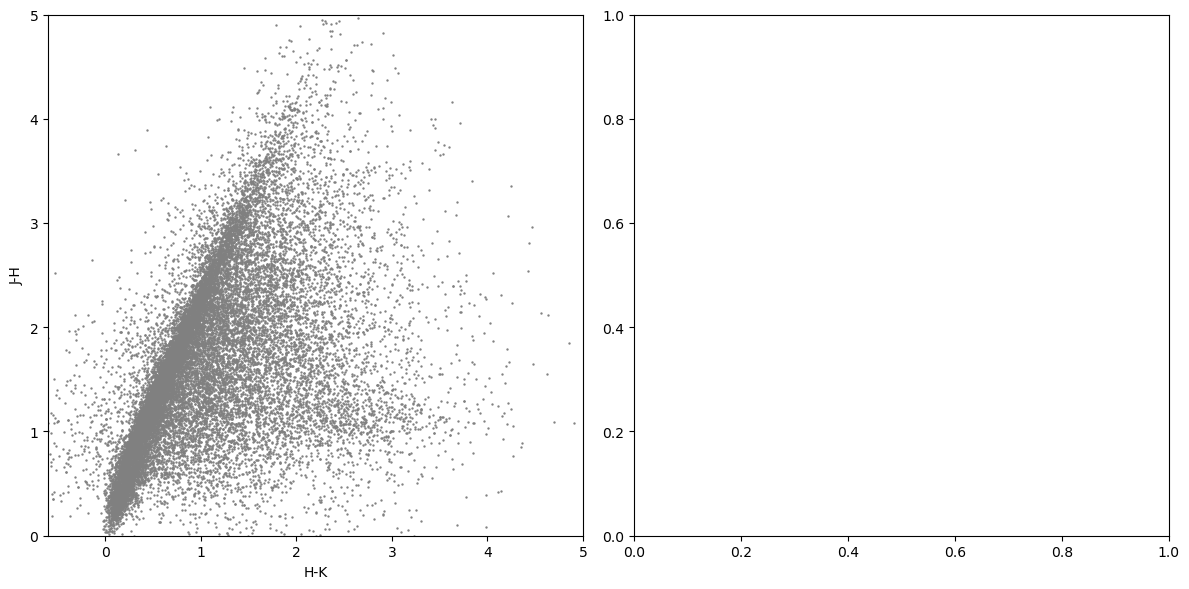

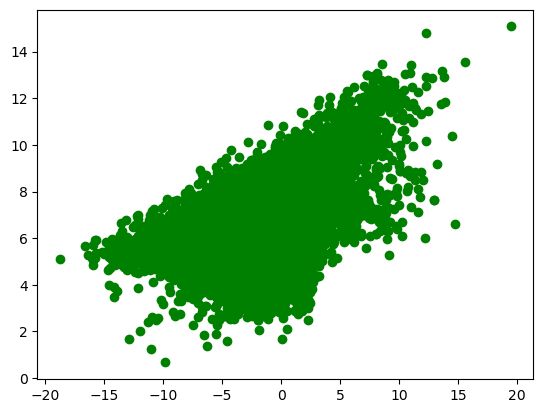

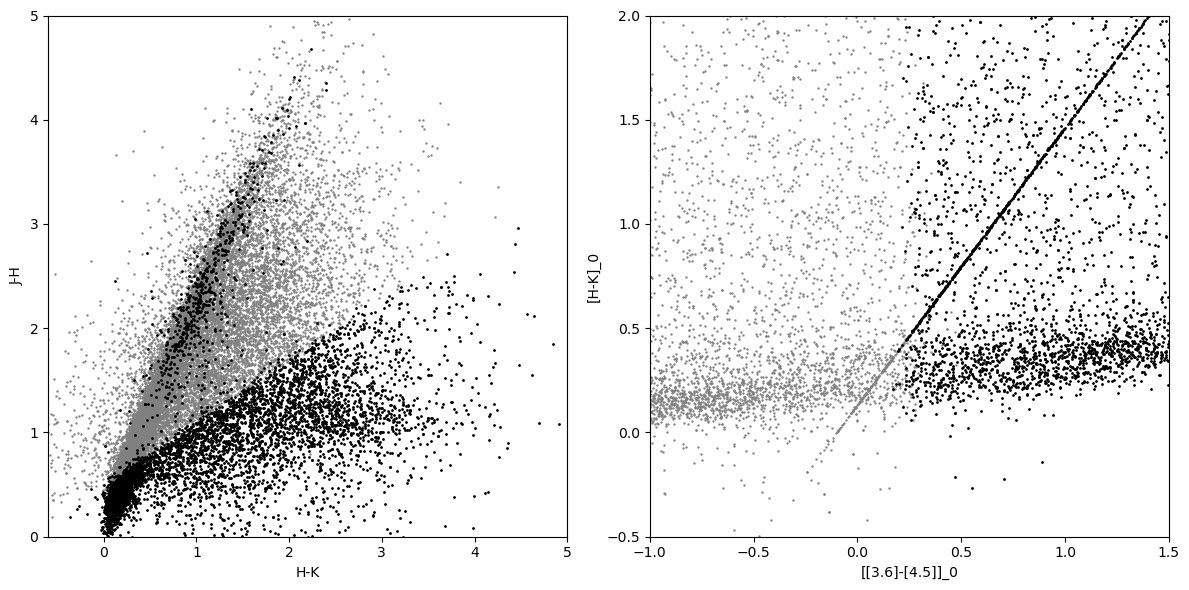

[Phase II] - 1 Class II objects, 6103 Class I objects


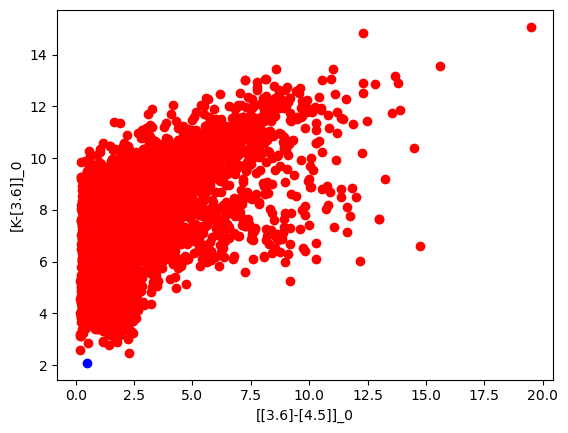

In [86]:
phase_II = Table.read('../output/tables/phase_II_glimpse_s07.tbl',format='ascii.ipac')

good = (
    (
        ~phase_II['mag5_8'].mask
        | ~ phase_II['mag8_0'].mask
    )
    & ~np.isnan(phase_II['h_msigcom'])
    & ~np.isnan(phase_II['k_msigcom'])
    & ~phase_II['color36_45'].mask
)

bad = (
    (phase_II['h_msigcom'] > 0.1)
    & (phase_II['k_msigcom'] > 0.1)
)

phase_II = phase_II[good & ~bad]

EJH_HK = 1.73



EK36_HK = 1.0 / 1.49 

EK45_HK = 1.0 / 1.17

E3645_HK = (1/(EK45_HK-EK36_HK))
print(E3645_HK)

print(f'[Phase II] - {len(phase_II)} objects to evaluate')

data_phase_II = {}



for idx, source in enumerate(phase_II):

    if (~np.isnan(source['j_msigcom'])) & (source['j_msigcom'] < 0.1):
        #method 1
        colorJH_meas = source['j_m']-source['h_m']
        colorHK_meas = source['h_m']-source['k_m']

        colorHK_0 = (colorJH_meas - EJH_HK*colorHK_meas -0.52)/(0.58-EJH_HK)

        if colorHK_0 <= 0.14:
            colorJH_0 = 0.6
        else:
            colorJH_0 = 0.58 * colorHK_0 + 0.52

    else:
        #method 2
        colorJH_0 = -999
        colorHK_0 = (1.33*(E3645_HK*colorHK_meas-source['color36_45']) -0.133) / (1.33*E3645_HK-1)
    
    colorK_36_0 = source['k_m'] - (source['mag3_6'] - colorHK_meas - colorHK_0)*EK36_HK

    color36_45_0 = source['color36_45'] - (colorHK_meas-colorHK_0)*E3645_HK

    data_phase_II[idx] = [colorHK_0,colorJH_0,colorK_36_0,color36_45_0]

for idx, col in enumerate(['colorHK_0','colorJH_0','colorK_36_0','color36_45_0']):
    phase_II[col] = [data_phase_II[i][idx] for i in range(len(phase_II))]


phase_II.write('../output/tables/TestPhase_II.tbl',format='ascii.ipac',overwrite=True)

_, ax = plt.subplots(1,2,figsize=(12,6),tight_layout=True)

ax[0].scatter(phase_II['h_m']-phase_II['k_m'],phase_II['j_m']-phase_II['h_m'],s=0.5,color='grey')
ax[0].set_ylabel('J-H')
ax[0].set_xlabel('H-K')
ax[0].set_xlim([-0.6,5])
ax[0].set_ylim([0,5])


plt.show()

# We now apply conditions

sigma_1 = phase_II['d3_6m'] + phase_II['d4_5m']

sigma_2 = phase_II['k_msigcom'] + phase_II['d3_6m']

class_II = phase_II.copy()

plt.scatter(phase_II['color36_45_0'],phase_II['colorK_36_0'],color='green')

phase_II = phase_II[~(
    (phase_II['color36_45_0'] - sigma_1 > 0.101)
    & (phase_II['colorK_36_0'] - sigma_2 > 0.0)
    & (phase_II['colorK_36_0'] - sigma_2 > -2.85714*(phase_II['color36_45_0']-sigma_1-0.101)+0.5)
)
]

class_II = safe_setdiff(class_II,phase_II,keys='designation')

_, ax = plt.subplots(1,2,figsize=(12,6),tight_layout=True)

ax[0].scatter(phase_II['h_m']-phase_II['k_m'],phase_II['j_m']-phase_II['h_m'],s=0.5,color='grey')
ax[0].scatter(class_II['h_m']-class_II['k_m'],class_II['j_m']-class_II['h_m'],s=1,color='black')
ax[0].set_ylabel('J-H')
ax[0].set_xlabel('H-K')
ax[0].set_xlim([-0.6,5])
ax[0].set_ylim([0,5])

ax[1].scatter(phase_II['color36_45_0'],phase_II['colorHK_0'],s=0.5,color='grey')
ax[1].scatter(class_II['color36_45_0'],class_II['colorHK_0'],s=1,color='black')
ax[1].set_ylabel('[H-K]_0')
ax[1].set_xlabel('[[3.6]-[4.5]]_0')
ax[1].set_xlim([-1,1.5])
ax[1].set_ylim([-0.5,2])

plt.show()

class_I = class_II.copy()

sigma_1 = class_II['d3_6m']+class_II['d4_5m']
sigma_2 = class_II['k_msigcom']+class_II['d3_6m']

class_II = class_II[
    ~(class_II['colorK_36_0'] - sigma_2 > -2.85714*(class_II['color36_45_0']-sigma_1-0.401)+1.7)
]

class_I = safe_setdiff(class_I,class_II,keys='designation')

print(f'[Phase II] - {len(class_II)} Class II objects, {len(class_I)} Class I objects')

plt.scatter(class_II['color36_45_0'],class_II['colorK_36_0'],color='blue')

plt.scatter(class_I['color36_45_0'],class_I['colorK_36_0'],color='red')

#plt.xlim([-1,1.5])
#plt.ylim([-0.5,2.5])

plt.ylabel('[K-[3.6]]_0')
plt.xlabel('[[3.6]-[4.5]]_0')
plt.show()

12.3
11.895001
11.038
12.444
11.053
10.076
10.239
8.101
11.95
12.314
10.816


In [50]:
phase_II['mag8_0']

--
--
10.306
--
11.274
10.115
10.227
8.179
--
--
10.824
